In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import torch 
import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox
import seaborn as sns
from sklearn.datasets import make_swiss_roll

from geodesic_toolbox.cometric import CentroidsCometric, IdentityCoMetric, RandersMetrics
from geodesic_toolbox.utils import get_mf_image

from finsler_embedding.utils import get_grid_pts, get_bounds
from finsler_embedding.omega import get_omega
from finsler_embedding.experiments.graph import construct_distance_matrix, get_knn_graph, compute_epsilon_empirical
from finsler_embedding.core.inputs import from_points
from finsler_embedding.experiments.learning import interpolate_V
from finsler_embedding.experiments.palette import INK, SPEED


In [2]:
torch.manual_seed(0)
N = 4000
noise = 0.1
beta = 0.9
m = 2
eps_scale = 1.0

In [3]:
X, t = make_swiss_roll(n_samples=N, noise=noise, random_state=0)
X = torch.from_numpy(X).float()

In [4]:
cmap = SPEED

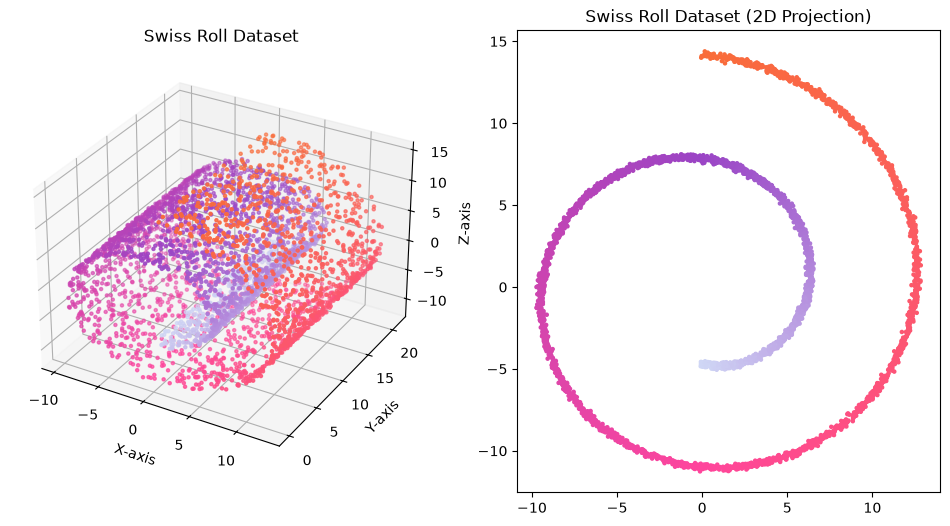

In [5]:
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(121, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap=cmap, s=5)
ax.set_title("Swiss Roll Dataset")
ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_zlabel("Z-axis")

ax = fig.add_subplot(122)
ax.scatter(X[:, 0], X[:, 2], c=t, cmap=cmap, s=5)
ax.set_title("Swiss Roll Dataset (2D Projection)")
plt.show()

In [6]:
base_cometric = IdentityCoMetric()
base_cometric = CentroidsCometric(centroids=X, cometric_centroids=base_cometric(X),kappa=5)
base_cometric_2D = CentroidsCometric(centroids=X[:, [0, 2]], cometric_centroids=IdentityCoMetric()(X[:, [0, 2]]),kappa=5)
omega_true = get_omega("swiss_roll", cometric=base_cometric,dim=3)
# omega_true = get_omega("swiss_roll_normal", cometric=base_cometric,dim=3)

randers_metric = RandersMetrics(
    base_cometric=base_cometric,
    omega=omega_true,
    beta=beta,
)

omega_x = omega_true(X)
density = base_cometric.inv_logdet(X)

Computing magnification factor:   0%|          | 0/79 [00:00<?, ?batch/s]

Computing magnification factor:  46%|████▌     | 36/79 [00:00<00:00, 358.23batch/s]

Computing magnification factor: 100%|██████████| 79/79 [00:00<00:00, 426.91batch/s]

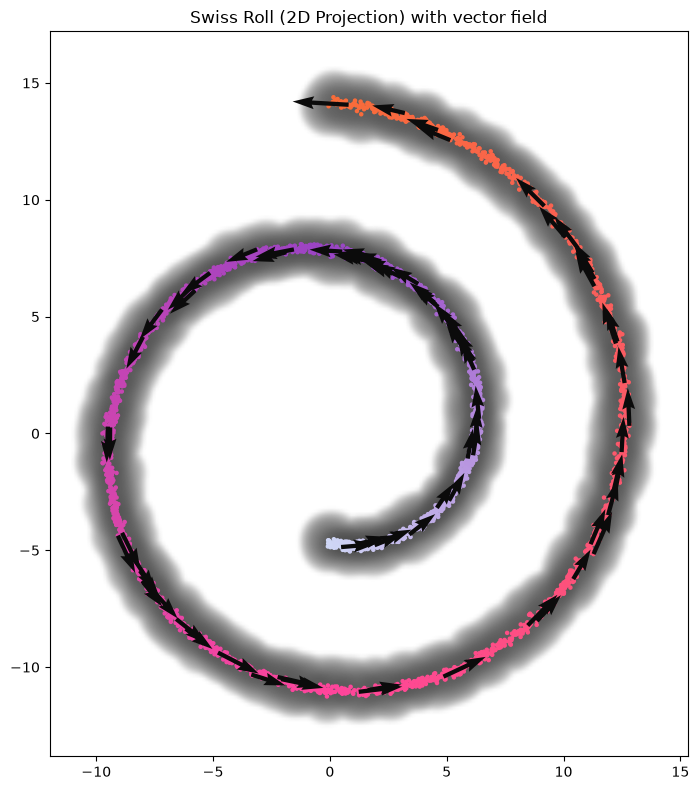

In [7]:
bounds_2D = get_bounds(X.detach()[:, [0, 2]], margin=0.1)
device = "cuda" if torch.cuda.is_available() else "cpu"
mf_2D = get_mf_image(cometric=base_cometric_2D.to(device), bounds=bounds_2D)
skip=50
plt.figure(figsize=(8, 8))
plt.imshow(mf_2D.cpu().numpy(), extent=bounds_2D, origin='lower', alpha=0.7, cmap='gray',interpolation='bilinear')
plt.scatter(X.detach()[:, 0], X.detach()[:, 2], c=t, cmap=cmap, s=5)
plt.quiver(X.detach()[::skip, 0], X.detach()[::skip, 2], omega_x.detach()[::skip, 0], omega_x.detach()[::skip, 2], 
           angles='xy', scale_units='xy', color=INK)
plt.title("Swiss Roll (2D Projection) with vector field")
plt.tight_layout()
plt.show()

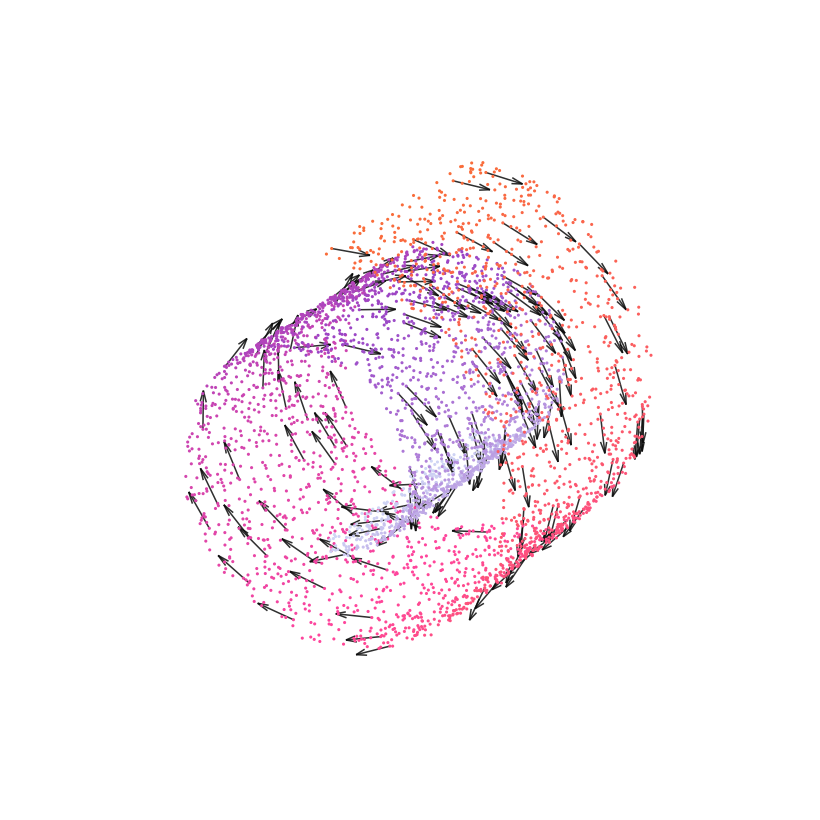

In [8]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_axes([0, 0, 1, 1], projection='3d')
# The drift is the centroid of the unit ball of the Randers metric, which points opposite to omega
X_np, drift_np = X.detach().numpy(), -omega_x.detach().numpy()
ax.scatter(X_np[:, 0], X_np[:, 1], X_np[:, 2], c=t, cmap=cmap, s=5, linewidths=0, depthshade=False)
skip = 25  # few arrows: the figure is printed about 1.4 in wide
ax.quiver(
    X_np[::skip, 0], X_np[::skip, 1], X_np[::skip, 2],
    drift_np[::skip, 0], drift_np[::skip, 1], drift_np[::skip, 2],
    length=2.6, normalize=True, color=INK, alpha=0.85, linewidth=1.1
)
ax.set_box_aspect(np.ptp(X_np, axis=0), zoom=0.9)  # true proportions of the roll
ax.view_init(elev=22, azim=-62)
ax.set_axis_off()

# Crop the pdf to what is drawn
fig.canvas.draw()
image = np.asarray(fig.canvas.buffer_rgba())[..., :3]
rows, cols = np.nonzero((image < 250).any(axis=2))
box = Bbox([[cols.min() / fig.dpi, (image.shape[0] - rows.max() - 1) / fig.dpi],
            [(cols.max() + 1) / fig.dpi, (image.shape[0] - rows.min()) / fig.dpi]])
fig.savefig("swiss_roll_vector_field_3D.pdf", bbox_inches=box, pad_inches=0.)
plt.show()


In [9]:
edges = get_knn_graph(X, n_neighbors=10,device="cpu")
print(f"Found {edges.shape[0]} edges in the KNN graph.")
dst_edges = construct_distance_matrix(X, edges, randers_metric,use_approx=True)

Found 45772 edges in the KNN graph.


Computing Randers distances:   0%|          | 0/115 [00:00<?, ?it/s]

Computing Randers distances:   3%|▎         | 4/115 [00:00<00:02, 39.98it/s]

Computing Randers distances:   8%|▊         | 9/115 [00:00<00:02, 45.23it/s]

Computing Randers distances:  12%|█▏        | 14/115 [00:00<00:02, 44.84it/s]

Computing Randers distances:  17%|█▋        | 19/115 [00:00<00:02, 45.35it/s]

... (15 outputs left out)

Computing Randers distances:  90%|████████▉ | 103/115 [00:02<00:00, 47.22it/s]

Computing Randers distances:  95%|█████████▍| 109/115 [00:02<00:00, 48.75it/s]

Computing Randers distances: 100%|██████████| 115/115 [00:02<00:00, 49.53it/s]

Computing Randers distances: 100%|██████████| 115/115 [00:02<00:00, 48.01it/s]

In [10]:
epsilon = compute_epsilon_empirical(dst_edges, scale=eps_scale)
distance_matrix = torch.zeros((N, N), dtype=X.dtype)
distance_matrix[edges[:, 0], edges[:, 1]] = dst_edges
results = from_points(
    X,
    distances=distance_matrix,
    bandwidth=epsilon,
    n_components=m,
    embedding="isomap",
    embedding_params={"n_neighbors": 10},
)
X_low = results.coordinates
bounds = get_bounds(X_low, margin=0.1)

In [11]:
V = results.drift
V_normed = V / (results.drift_norm_squared.sqrt() + 1e-12).unsqueeze(1)
unit_V = V / (V.norm(dim=1, keepdim=True) + 1e-12)

In [12]:
# Sort by x coords for display
idx = torch.argsort(X_low[:, 0])
X_low_plt = X_low[idx].clone()
V_plt = V[idx].clone()
unit_V_plt = unit_V[idx].clone()
t_plt = t[idx]

In [13]:
V_plt

tensor([[-0.0028, -0.0003],
        [-0.0041, -0.0007],
        [-0.0029, -0.0014],
        ...,
        [-0.0033,  0.0003],
        [-0.0045,  0.0011],
        [-0.0036,  0.0006]])

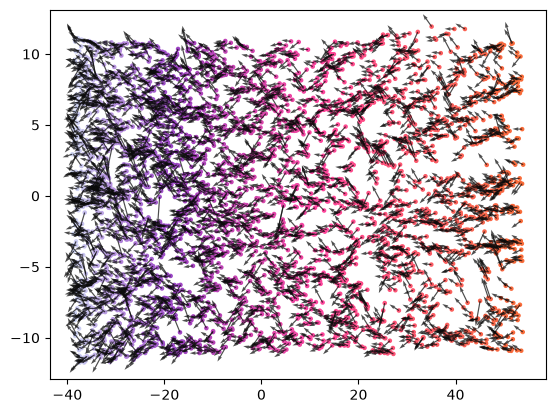

In [14]:
cbar = plt.scatter(
    X_low_plt[:, 0], X_low_plt[:, 1], c=t_plt, cmap=cmap,s=5
)
skip=1
plt.quiver(
    X_low_plt[::skip, 0],
    X_low_plt[::skip, 1],
    unit_V_plt[::skip, 0],
    unit_V_plt[::skip, 1],
    color=INK,
    scale=.5,
    angles="xy",
    scale_units="xy",
    alpha = results.admissible[idx][::skip].float().sigmoid()
)

In [15]:
model, loss_list = interpolate_V(X_low, unit_V, dim=m)

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=1.89]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.824]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.385]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.332]

Interpolating V:   0%|          | 0/500 [00:00<?, ?it/s, loss=0.441]

... (502 outputs left out)

Interpolating V:  93%|█████████▎| 466/500 [00:01<00:00, 503.40it/s, loss=0.0315]

Interpolating V:  93%|█████████▎| 466/500 [00:01<00:00, 503.40it/s, loss=0.0315]

Interpolating V:  93%|█████████▎| 466/500 [00:01<00:00, 503.40it/s, loss=0.0315]

Interpolating V: 100%|██████████| 500/500 [00:01<00:00, 462.53it/s, loss=0.0315]

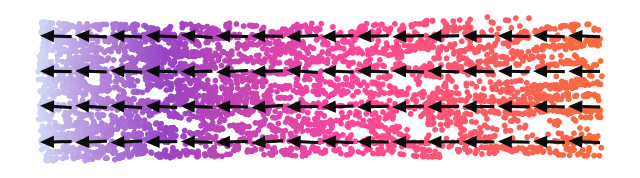

In [16]:
# Grid of arrows: few and bold, the figure is printed under one inch wide. The cells of the grid are square
# (the embedding is a long strip, drawn with its true proportions) and the arrows are centered in them.
n_arrows = 16  # along the long axis
lo, hi = X_low.min(dim=0).values, X_low.max(dim=0).values
spacing = (hi - lo).max().item() / n_arrows
nx, ny = (int(((hi - lo)[i] / spacing).round()) for i in range(2))
x = lo[0] + spacing * (torch.arange(nx) + 0.5) + ((hi - lo)[0] - nx * spacing) / 2
y = lo[1] + spacing * (torch.arange(ny) + 0.5) + ((hi - lo)[1] - ny * spacing) / 2
X, Y = torch.meshgrid(x, y, indexing="ij")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=1)

V_grid = model(grid_points).detach()
V_grid_unit = V_grid / (V_grid.norm(dim=1, keepdim=True) + 1e-12)

plt.figure(figsize=(8, 8))
plt.scatter(X_low[:, 0], X_low[:, 1], c=t, cmap=cmap, s=10)
plt.quiver(
    grid_points[:, 0],
    grid_points[:, 1],
    V_grid_unit[:, 0],
    V_grid_unit[:, 1],
    color=INK,
    scale=1 / (0.9 * spacing),  # arrow length: 90% of the spacing of the grid
    width=0.005, headwidth=4, headlength=4.5,
    pivot="mid",
    angles="xy",
    scale_units="xy",
)
plt.gca().set_aspect("equal")
plt.axis("off")
plt.savefig("swiss_roll_vector_field.pdf", dpi=300, bbox_inches="tight", pad_inches=0.)
plt.show()
